In [ ]:
import os
os.environ['KAGGLE_USERNAME']='diva1parekh106'
os.environ['KAGGLE_KEY']='KGAT_9eba5a474cd520e58b824afbe5c0be26'

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download shivamb/netflix-shows

Dataset URL: https://www.kaggle.com/datasets/shivamb/netflix-shows
License(s): CC0-1.0
100% 1.34M/1.34M [00:00<00:00, 147MB/s]



In [ ]:
#unzipping the file
!unzip -q netflix-shows.zip

In [ ]:
#import basic libraries
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#import the dataset using pandas
df = pd.read_csv("/content/netflix_titles.csv")

In [ ]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [ ]:
df.shape  #outcome of df.shape is always a tupple
#Why df.shape returns a tupple and not a list? Because tupples are immutable. If it is a list, it can be easily modified and manipulated, and hence in order to preserve the identity
#of the dataset, the format is a tupple.

(8807, 12)

In [ ]:
df.info()  #you can never train ML models over a null value.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.isnull()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,False,False,False,False,True,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,False,False
3,False,False,False,True,True,True,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,False,False,False,False,False,False,False,False,False,False,False,False
8803,False,False,False,True,True,True,False,False,False,False,False,False
8804,False,False,False,False,False,False,False,False,False,False,False,False
8805,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum() #shows how many missing values are present in each column.

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

<Axes: xlabel='type', ylabel='count'>

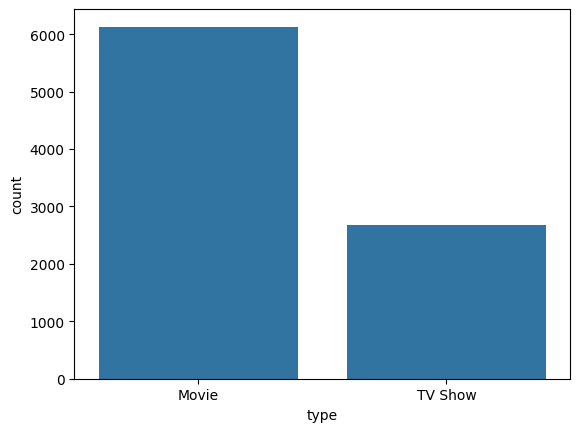

In [ ]:
#Data Visualization
sns.countplot(x='type', data = df)

<Axes: xlabel='director', ylabel='count'>

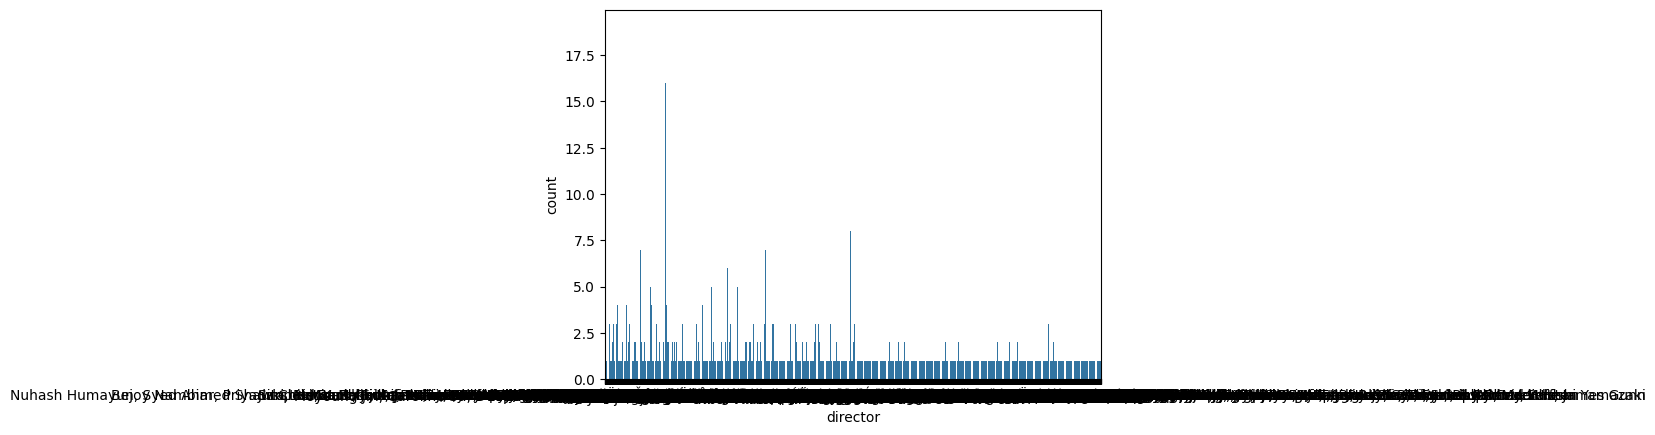

In [ ]:
sns.countplot(x='director', data = df)

In [ ]:
#making the missing values in director column into UNKNOWN
df['director'] = df['director'].fillna('Unknown')

(array([ 0. ,  2.5,  5. ,  7.5, 10. , 12.5, 15. , 17.5, 20. ]),
 [Text(0.0, 0, '0.0'),
  Text(2.5, 0, '2.5'),
  Text(5.0, 0, '5.0'),
  Text(7.5, 0, '7.5'),
  Text(10.0, 0, '10.0'),
  Text(12.5, 0, '12.5'),
  Text(15.0, 0, '15.0'),
  Text(17.5, 0, '17.5'),
  Text(20.0, 0, '20.0')])

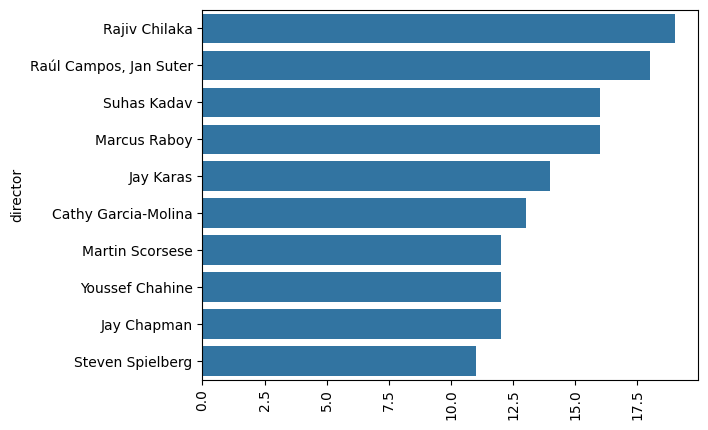

In [ ]:
#Top contributing directors
top_directors = df ['director'].value_counts().[1:].head(10)
sns.barplot(x=top_directors.values, y=top_directors.index)
plt.xticks(rotation=90)

In [ ]:
#making the missing values in country column with UNKNOWN
df['country'] = df['country'].fillna('Unknown')  #these libraries have the functionality that it will drop the null values
df['cast'] = df['cast'].fillna('Unknown')
df['date_added'] = df['date_added'].fillna('Unknown')

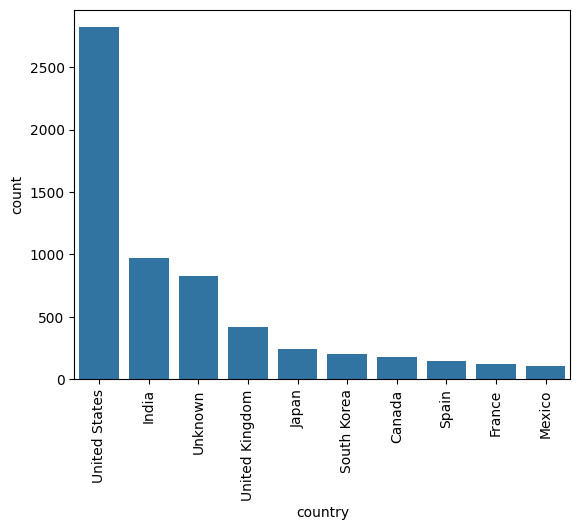

In [ ]:
sns.countplot(
    x='country',
    data=df,
    order=df['country'].value_counts().head(10).index,

)
plt.xticks(rotation=90)
plt.show()

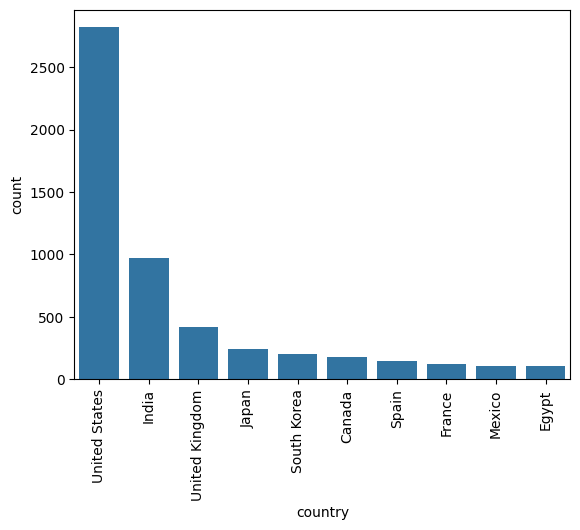

In [ ]:
sns.countplot(
    x='country',
    data = df[df['country']!='Unknown'],
    order = df[df['country']!='Unknown']['country'].value_counts().head(10).index
)
plt.xticks(rotation=90)
plt.show()


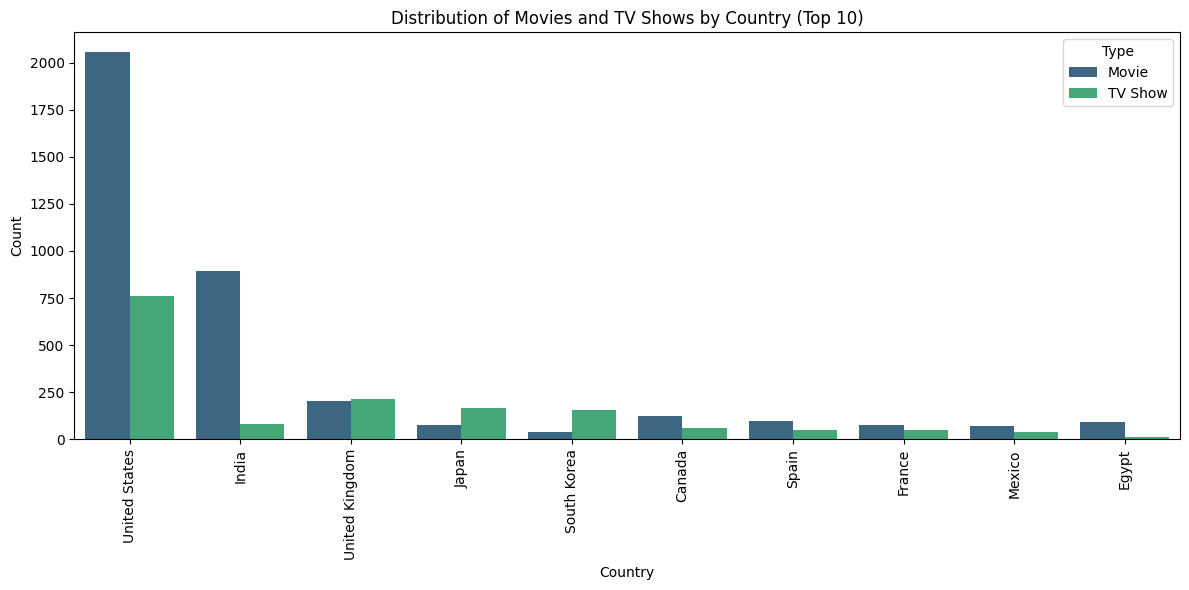

In [ ]:
plt.figure(figsize=(12, 6)) #sets the width 12 and height 6 inches
sns.countplot(
    x='country', #country column on x-axis
    hue='type', #seperates the bars within each country based on the 'type' column.
    data=df[df['country'] != 'Unknown'], #this filters the dataframe df before plotting. It includes only rows where the country column is not equal to 'UNKNOWN'
    order=df[df['country'] != 'Unknown']['country'].value_counts().head(10).index, #FILTERING and then takes the top 10 most frequent countries and finally extract their names (index) to set the display order.
    palette='viridis'
)
plt.title('Distribution of Movies and TV Shows by Country (Top 10)')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='Type')
plt.tight_layout()
plt.show()